# Compare AT3D retrieved cloud volume extinction coefficient to CAMP2Ex insitu measured

In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
import xarray as xr

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))


In [2]:
import src.CAMP2Ex as cx
import src.Retrieval as retrieval
plt.style.use('seaborn-v0_8-talk')

In [3]:
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default'
r = retrieval.Retrieval(EXPERIMENT)
r.load_retrieval(extinction_th=[0.3, np.inf])

In [4]:
def optical_path_directional(extinction_grid, point, phi, ext_threshold=0.3, max_distance=None):
    """
    Compute optical path from a point along direction phi to cloud edge.
    
    Parameters:
    -----------
    extinction_grid : xr.DataArray
        3D extinction field with dimensions (x, y, z) in km
    point : tuple
        (x, y, z) coordinates in km
    phi : float
        Azimuthal angle in degrees (0=East, 90=North, 180=West, 270=South)
    ext_threshold : float
        Extinction threshold to define cloud edge (km^-1)
    max_distance : float, optional
        Maximum distance to search in km
        
    Returns:
    --------
    float : Optical path to cloud edge (dimensionless)
    """
    
    # Point is already in km
    x0, y0, z0 = point
    
    # Convert phi to radians and compute direction vector
    phi_rad = np.radians(phi)
    dx_dir = np.cos(phi_rad)  # East-West component
    dy_dir = np.sin(phi_rad)  # North-South component
    
    # Get grid parameters
    x_coords = extinction_grid.x.values
    y_coords = extinction_grid.y.values
    z_coords = extinction_grid.z.values
    
    dx_grid = float(x_coords[1] - x_coords[0])  # Grid spacing in km
    dy_grid = float(y_coords[1] - y_coords[0])
    
    # Find nearest z-level
    z_idx = np.argmin(np.abs(z_coords - z0))
    ext_slice = extinction_grid.isel(z=z_idx)
    
    # Determine step size (use smaller of grid spacings)
    step_size = min(abs(dx_grid), abs(dy_grid)) * 0.5  # km
    
    if max_distance is not None:
        max_steps = int(max_distance / step_size)
    else:
        max_steps = 10000
    
    # Initialize
    optical_path = 0.0
    x, y = x0, y0
    
    # March along direction
    for step in range(max_steps):
        # Check if outside grid bounds
        if (x < x_coords.min() or x > x_coords.max() or
            y < y_coords.min() or y > y_coords.max()):
            break
        
        # Interpolate extinction at current position
        try:
            ext = float(ext_slice.interp(x=x, y=y, method='linear'))
        except:
            break
        
        # Check if reached cloud edge
        if ext < ext_threshold:
            break
        
        # Accumulate optical path: tau = integral(extinction * ds)
        # extinction in km^-1, step_size in km -> dimensionless
        optical_path += ext * step_size
        
        # Move to next point
        x += dx_dir * step_size
        y += dy_dir * step_size
    
    return optical_path

def optical_path_all_directions(extinction_grid, point, n_directions=8, ext_threshold=0.3):
    """
    Compute optical path in multiple directions and return minimum.
    
    Parameters:
    -----------
    extinction_grid : xr.DataArray
        3D extinction field
    point : tuple
        (x, y, z) in km
    n_directions : int
        Number of azimuthal directions to sample
    ext_threshold : float
        Extinction threshold for cloud edge (km^-1)
        
    Returns:
    --------
    dict with keys:
        'min_optical_path': minimum optical path (dimensionless)
        'min_direction': direction of minimum (degrees)
        'all_paths': list of (phi, optical_path) tuples
    """
    phis = np.linspace(0, 360, n_directions, endpoint=False)
    paths = []
    
    for phi in phis:
        path = optical_path_directional(extinction_grid, point, phi, ext_threshold)
        paths.append((phi, path))
    
    # Find minimum
    min_idx = np.argmin([p[1] for p in paths])
    
    return {
        'min_optical_path': paths[min_idx][1],
        'min_direction': paths[min_idx][0],
        'all_paths': paths
    }


In [5]:
# cloud = r.solvers_retrieval[0.67].medium['cloud']
# min_optical_path = np.zeros(shape=(cloud.dims['x'], cloud.dims['y'], cloud.dims['z']))
# for i, x in enumerate(cloud.x.data):
#     for j, y in enumerate(cloud.y.data):
#         for k, z in enumerate(cloud.z.data):
#             tmp_result = optical_path_all_directions(
#                 cloud.extinction,
#                 (x, y, z),
#                 n_directions=8,
#                 ext_threshold=0.3
#             )
#             min_optical_path[i, j, k] = tmp_result['min_optical_path']
# r.solvers_retrieval[0.67].medium['cloud']['min_optical_path'] = (['x','y','z'], min_optical_path)
# r.solvers_retrieval[0.67].medium['cloud'].to_netcdf('./min_optical_path.nc')

r.solvers_retrieval[0.67].medium['cloud'] = xr.load_dataset('./min_optical_path.nc')


In [6]:
# r.solvers_retrieval[0.67].medium['cloud']['min_optical_path'].isel(z=slice(4, 12)).plot(x='x', y='y', col='z', col_wrap=4)

In [7]:
# # Test
# x = np.arange(10)
# y = np.arange(10)
# z = np.arange(10)
# ext = np.zeros(shape=(10, 10, 10))
# ext[3:7, 3:7, 3:7] = 1
# extinction_grid = xr.DataArray(
#     data = ext,
#     coords=dict(
#         x=x,
#         y=y,
#         z=z
#     )
# )
# optical_path_all_directions(extinction_grid, (5, 5, 5), n_directions=8, ext_threshold=0)

In [8]:
# ext = r.solvers_retrieval[0.67].medium['cloud'].extinction.copy(deep=True).isel(z=slice(4, 12))
# ext = ext > 0.3
# ext.plot(x='x', y='y', col='z', col_wrap=4, cmap='gray')

In [ ]:
at3d_vc = r.solvers_retrieval[0.67].medium['cloud'].min_optical_path.to_dataframe()
at3d_ext = r.solvers_retrieval[0.67].medium['cloud'].extinction.to_dataframe()
at3d_cloud = pd.merge(at3d_vc.reset_index(), at3d_ext.reset_index(), on=['x','y','z'])
at3d_cloud = at3d_cloud[at3d_cloud['extinction'] > 0.3]
at3d_cloud = at3d_cloud[at3d_cloud['min_optical_path'] < 5] # Remove AT3D veiled core
at3d_cloud['x'] *= 1000
at3d_cloud['y'] *= 1000
at3d_cloud['z'] *= 1000
at3d_cloud['source'] = 'AT3D'

In [ ]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
nav_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2EX-MetNav_P3B_20191001_R0.ict'
fcdp_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-FCDP_P3B_20191001_R1.ict'
tds_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-2DS10_P3B_20191001_R0.ict'
p3 = cx.load_FCDP_2DS(fcdp_file, tds_file, nav_file, breakpoint=40, resample='2s')
p3['source'] = 'P3'
p3['sample_optical_path'] = p3['ext_km'] * p3['Length_m'] * 1e-3

# The sample at time t is part of the cloud element e if
# the extinction at time t > 0.3 
# and there is another sample t' \in e such that |t-t'| < 3
# In other words, it takes 3 seconds of clear air to separate two clouds
ext_th = 0.3
t_th = pd.Timedelta(3, 's')
p3['cloud_pass'] = -1
cloud_pass = 1
inCloud = False
t_last_cloud = p3.index[0]
for row in p3.itertuples():
    if(not inCloud):
        if(row.ext_km > ext_th):
            inCloud = True
            t_last_cloud = row.Index
            p3.at[row.Index, 'cloud_pass'] = cloud_pass
    else:
        if(row.ext_km > ext_th):
            t_last_cloud = row.Index
            p3.at[row.Index, 'cloud_pass'] = cloud_pass
        elif(row.Index - t_last_cloud < t_th):
            p3.at[row.Index, 'cloud_pass'] = cloud_pass
        else:
            p3.loc[t_last_cloud+pd.Timedelta(1, 's'):row.Index, 'cloud_pass'] = -1
            inCloud = False
            cloud_pass += 1

g = p3.groupby('cloud_pass')['sample_optical_path']
p3['forward_optical_path'] = g.cumsum()
p3['backward_optical_path'] = g.apply(lambda s: s[::-1].cumsum()[::-1]).reset_index(level=0, drop=True)
p3['optical_path'] = p3[['forward_optical_path', 'backward_optical_path']].min(axis=1)
p3['pass_length'] = p3.groupby('cloud_pass')['Length_m'].transform('sum')

start_time = pd.to_datetime('2019-10-02 00:00:00')
end_time = pd.to_datetime('2019-10-02 02:00:00')

bins = np.arange(350, 1251, 100)
p3['altitude_bin'] = pd.cut(p3['GPS_Altitude'], bins=bins)
at3d_cloud['altitude_bin'] = pd.cut(at3d_cloud['z'], bins=bins)

p3_subset = p3[
    # (p3['N_L'] > 10000)
    (p3['ext_km'] > 0.3)
    & (p3.index > start_time)
    & (p3.index < end_time)
    & (p3['GPS_Altitude'] < 1250)
    & (p3['optical_path'] < 5)       # Remove P3 veiled core
    # & (p3['pass_length'] < 3600)
]

p3_agg = p3_subset.reset_index().groupby('cloud_pass').agg(
    start_time=('datetime', 'min'),
    end_time=('datetime', 'max'),
    alt_min=('GPS_Altitude', 'min'),
    alt_max=('GPS_Altitude', 'max'),
    pass_length=('Length_m', 'sum'),
    alt_bin=('altitude_bin', 'max'),
    sum_ext = ('ext_km', 'sum'),
    max_optical_path = ('optical_path', 'max')
)
p3_agg['optical_depth'] = p3_agg['sum_ext'] * p3_agg['pass_length'] * 1e-3

/data/gdi/b/johntl3/LundstromPub2025/src/CAMP2Ex.py:108: RuntimeWarning: invalid value encountered in divide
  Re = np.sum(n * r**3, axis=-1) / np.sum(n * r**2, axis=-1)
/tmp/ipykernel_1094384/1999910648.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  p3['cloud_pass'] = -1
/tmp/ipykernel_1094384/1999910648.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  p3['forward_optical_path'] = g.cumsum()
/tmp/ipykernel_1094384/1999910648.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of call

Text(0.5, 1.0, 'Veiled Core Removed')

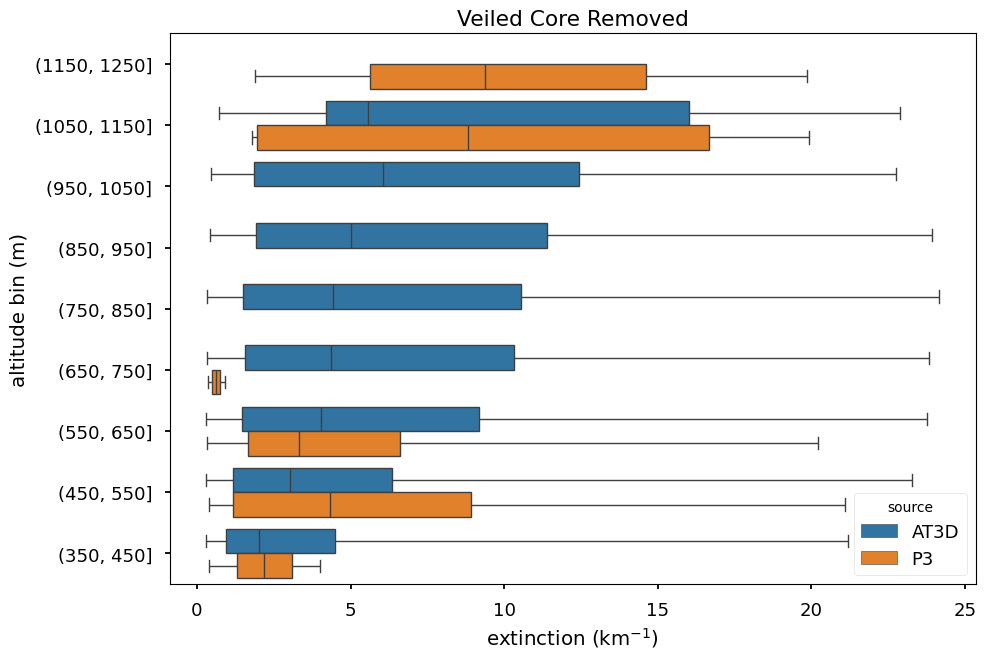

In [11]:
tmp_at3d_cloud = at3d_cloud.loc[:, ['extinction', 'altitude_bin', 'source']]
tmp_p3 = p3_subset.reset_index().loc[:, ['ext_km', 'altitude_bin', 'source']].rename(columns={'ext_km':'extinction'})
tmp_merged = pd.concat([tmp_at3d_cloud, tmp_p3])
order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
ax = sns.boxplot(tmp_merged, x='extinction', y='altitude_bin', hue='source', order=order, whis=(0,100))
ax.set_ylabel('altitude bin (m)')
ax.set_xlabel(r'extinction (km$^{-1}$)')
ax.set_title('Veiled Core Removed')

# Two-sided K-S Test

In [12]:
rows = []
for i in range(len(bins) - 1):
    level = pd.Interval(left=bins[i], right=bins[i+1], closed='right')
    at3d_ext = at3d_cloud.loc[at3d_cloud['altitude_bin'] == level, 'extinction']
    p3_ext = p3_subset.loc[p3_subset['altitude_bin'] == level, 'ext_km']
    if((len(at3d_ext) > 0) & (len(p3_ext) > 0)):
        # result = stats.kstest(at3d_ext, p3_ext)
        result = stats.ks_2samp(at3d_ext, p3_ext, method='exact')
        row = {
            'level': level,
            'statistic': result.statistic,
            'pvalue': result.pvalue,
            'statistic_location': result.statistic_location,
            'statistic_sign': result.statistic_sign,
            'N_at3d': len(at3d_ext),
            'M_p3': len(p3_ext)
        }
        rows.append(row)
ks_stats = pd.DataFrame(rows, columns=[n for n in row])
ks_stats['alpha'] = 2*np.exp((-2*ks_stats['M_p3']*ks_stats['statistic']**2)/(1+(ks_stats['M_p3']/ks_stats['N_at3d'])))
ks_stats


,level,statistic,pvalue,statistic_location,statistic_sign,N_at3d,M_p3,alpha
0,"(350, 450]",0.450131,0.684169,0.380726,-1,381,2,0.893068
1,"(450, 550]",0.172535,0.165242,2.773769,1,537,43,0.186911
2,"(550, 650]",0.135475,0.112012,5.960282,-1,506,89,0.124292
3,"(650, 750]",0.862595,0.040500,0.902081,-1,262,2,0.104289
4,"(1050, 1150]",0.428571,0.541176,2.025236,-1,14,4,0.637813


# Epps Singleton Test

In [13]:
rows = []
for i in range(len(bins) - 1):
    level = pd.Interval(left=bins[i], right=bins[i+1], closed='right')
    at3d_ext = at3d_cloud.loc[at3d_cloud['altitude_bin'] == level, 'extinction']
    p3_ext = p3_subset.loc[p3_subset['altitude_bin'] == level, 'ext_km']
    if((len(at3d_ext) > 4) & (len(p3_ext) > 4)):
        # result = stats.kstest(at3d_ext, p3_ext)
        result = stats.epps_singleton_2samp(at3d_ext, p3_ext)
        row = {
            'level': level,
            'statistic': result.statistic,
            'pvalue': result.pvalue,
            'N_at3d': len(at3d_ext),
            'M_p3': len(p3_ext)
        }
        rows.append(row)
es_stats = pd.DataFrame(rows, columns=[n for n in row])
es_stats


,level,statistic,pvalue,N_at3d,M_p3
0,"(450, 550]",4.079266,0.395385,537,43
1,"(550, 650]",17.277263,0.001707,506,89


# Anderson-Darling k-sample test

In [14]:
rows = []
for i in range(len(bins) - 1):
    level = pd.Interval(left=bins[i], right=bins[i+1], closed='right')
    at3d_ext = at3d_cloud.loc[at3d_cloud['altitude_bin'] == level, 'extinction']
    p3_ext = p3_subset.loc[p3_subset['altitude_bin'] == level, 'ext_km']
    if((len(at3d_ext) > 0) & (len(p3_ext) > 0)):
        # result = stats.kstest(at3d_ext, p3_ext)
        result = stats.anderson_ksamp([at3d_ext, p3_ext])
        row = {
            'level': level,
            'statistic': result.statistic,
            'critical_value_5': result.critical_values[2],
            'pvalue': result.pvalue,
            'N_at3d': len(at3d_ext),
            'M_p3': len(p3_ext)
        }
        rows.append(row)
es_stats = pd.DataFrame(rows, columns=[n for n in row])
es_stats


/tmp/ipykernel_1094384/746564401.py:8: UserWarning: p-value capped: true value larger than 0.25. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  result = stats.anderson_ksamp([at3d_ext, p3_ext])


,level,statistic,critical_value_5,pvalue,N_at3d,M_p3
0,"(350, 450]",-0.385573,1.961,0.250000,381,2
1,"(450, 550]",1.581313,1.961,0.072325,537,43
2,"(550, 650]",0.587563,1.961,0.189402,506,89
3,"(650, 750]",2.998672,1.961,0.019497,262,2
4,"(1050, 1150]",-0.481588,1.961,0.250000,14,4


# One Sided K-S Test

In [15]:
# rows = []
# for i in range(len(bins) - 1):
#     level = pd.Interval(left=bins[i], right=bins[i+1], closed='right')
#     at3d_ext = at3d_cloud.loc[at3d_cloud['altitude_bin'] == level, 'extinction']
#     p3_ext = p3_subset.loc[p3_subset['altitude_bin'] == level, 'ext_km']
#     if((len(at3d_ext) > 0) & (len(p3_ext) > 0)):
#         result = stats.kstest(at3d_ext, p3_ext, alternative='less')
#         row = {
#             'level': level,
#             'statistic': result.statistic,
#             'pvalue': result.pvalue,
#             'statistic_location': result.statistic_location,
#             'statistic_sign': result.statistic_sign,
#             'N_at3d': len(at3d_ext),
#             'N_p3': len(p3_ext)
#         }
#         rows.append(row)
# ks_stats = pd.DataFrame(rows, columns=[n for n in row])
# ks_stats


In [16]:
# bins = np.arange(350, 1251, 100)

# cloud = retrieval.threshold_cloud(r.solvers_retrieval[0.67].medium['cloud'], extinction_th=[0.3, np.inf], tau_th=[0.3, np.inf])
# at3d_ext_box = []
# for i in range(len(bins)-1):
#     tmp_cloud = cloud.sel(z=slice(1e-3*bins[i], 1e-3*bins[i+1]))
#     ext = tmp_cloud.extinction.data
#     at3d_ext_box.append(ext[tmp_cloud.cloud_volume_mask.data==1])

# p3_ext_box = []
# for i in range(len(bins)-1):
#     tmp = p3_subset.loc[
#         (p3_subset['GPS_Altitude'] >= bins[i])
#         & (p3_subset['GPS_Altitude'] < bins[i+1])
#     ]['ext_km'].to_numpy()
#     p3_ext_box.append(tmp)

# box_kwargs = {
#     'vert':False,
#     'manage_ticks':False,
#     'patch_artist':True,
#     'widths':30,
#     'whis':(0,100)
# }

# f, ax = plt.subplots(1, 1, figsize=(7, 8))
# at3d_bplot = ax.boxplot(at3d_ext_box, positions=bins[:-1]+68, **box_kwargs)
# for patch in at3d_bplot['boxes']:
#     patch.set_facecolor('tab:green')
#     patch.set_alpha(0.5)

# p3_bplot = ax.boxplot(p3_ext_box, positions=bins[:-1]+32, **box_kwargs)
# for patch in p3_bplot['boxes']:
#     patch.set_facecolor('tab:blue')
#     patch.set_alpha(0.5)

# scat_kwargs = {'s':10, 'cmap':'brg'}
# p3_dots = ax.scatter(p3_subset['ext_km'], p3_subset['GPS_Altitude'], c=p3_subset['Length_m'], **scat_kwargs)
# plt.colorbar(p3_dots, ax=ax, label='Sample Length (m)', shrink=0.7)

# ax.set_xlabel('Extinction (1/km)')
# ax.set_ylabel('Altitude (m)')
# ax.grid(visible=True, which='major', axis='x')
# ax.grid(visible=True, which='minor', axis='y', color='r', linestyle='--')

# ax.set_yticks(np.arange(0, 1400, 100))
# ax.set_yticks(np.arange(50, 1300, 100), minor=True)
# ax.set_ylim([0, 1270])
# ax.set_xlabel(r'Extinction (km$^{-1}$)')

# ax.legend([at3d_bplot['boxes'][0], p3_bplot['boxes'][0]], ['AT3D', 'NASA P3'], loc='lower right')